# Systematics in spin space

This tutorial computes the maps of a few systematics with SBM, removes them with
templates, and turns the residual B modes into a bias on the tensor-to-scalar ratio.
It uses the small test scan shipped with SBM (`tests/nside_32_boresight_hwp.h5`, a
boresight detector with a rotating HWP at `nside = 32`, in the cross-link format of
SBM 0.4). The h-map files of litebird_sim and Falcons.jl are read with `sbm.HMaps.load`.

In [1]:
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

import sbm
from sbm import systematics as sy

hmaps = sbm.HMaps.load_legacy("../tests/nside_32_boresight_hwp.h5")
nside = hmaps.nside
print(nside, hmaps.couples[:6], "...")

32 [(0, 4), (0, 8), (1, -8), (1, -4), (1, 0), (1, 4)] ...


## Orientation functions

`hmaps.hits` holds the hit counts and `hmaps.h(n, m)` the orientation function
$_{n,m}\tilde h = \langle e^{-i(n\psi + m\phi)} \rangle$; the conjugate couples
are computed. $|_{2,0}\tilde h|$ measures the cross-linking without HWP,
$|_{4,-8}\tilde h|$ the one that matters for the polarization with HWP.

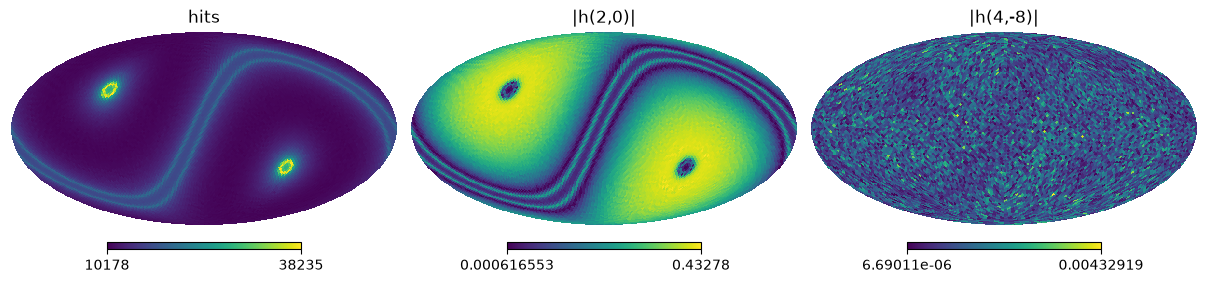

In [2]:
fig = plt.figure(figsize=(12, 3.2))
hp.mollview(hmaps.hits, title="hits", sub=(1, 3, 1), fig=fig.number)
hp.mollview(np.abs(hmaps.h(2, 0)), title="|h(2,0)|", sub=(1, 3, 2), fig=fig.number)
hp.mollview(np.abs(hmaps.h(4, -8)), title="|h(4,-8)|", sub=(1, 3, 3), fig=fig.number)

## Sky

`Sky` holds $I$ and $P = Q + iU$ and computes the spin derivatives on demand (and
the second-order maps, with ducc0, from the harmonic coefficients).

In [3]:
cmb = hp.ud_grade(sbm.generate_cmb(128, r=0.0, cmb_seed=33), nside)
sky = sbm.Sky.from_maps(*cmb)
lmax = 3 * nside - 1


def bb_of(iqu):
    maps = np.nan_to_num(iqu)
    return hp.anafast(maps, lmax=lmax)[2]


def residual(model, basis, reference):
    result = sbm.map_make((hmaps, model), basis)
    return result.iqu - reference

## Pointing offset behind a HWP

The signal model is the sky plus the perturbation of the systematic. With the
standard IQU basis the offset leaks temperature into polarization; adding the
templates of `abs_pointing` to the basis absorbs it.

delta r (IQU): 1.4967075148771979e-06  with template: 2.150034564394537e-07


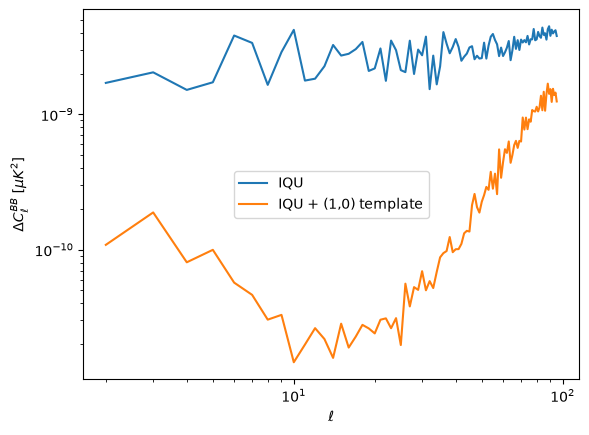

In [4]:
rho = np.deg2rad(1 / 60)
iqu_basis = sbm.Basis.iqu(hwp=True)
ideal = sbm.map_make((hmaps, sy.sky_signal(sky, hwp=True)), iqu_basis).iqu
model = sy.sky_signal(sky, hwp=True) + sy.abs_pointing(sky, rho_rad=rho, chi_rad=0.0)
res3 = residual(model, iqu_basis, ideal)
res5 = residual(model, iqu_basis.extend([(1, 0)]), ideal)

ell = np.arange(lmax + 1)
plt.loglog(ell[2:], bb_of(res3)[2:], label="IQU")
plt.loglog(ell[2:], bb_of(res5)[2:], label="IQU + (1,0) template")
plt.xlabel(r"$\ell$"); plt.ylabel(r"$\Delta C_\ell^{BB}$ [$\mu K^2$]"); plt.legend()
print("delta r (IQU):", sbm.forecast(bb_of(res3), lmax=lmax)["delta_r"], " with template:", sbm.forecast(bb_of(res5), lmax=lmax)["delta_r"])

## HWP instrumental polarization

`hwp_ip` returns the leakage alone, at spin $(0,4)$; the template $(0,4)$ removes it.

In [5]:
leak = sy.hwp_ip(sky, epsilon=1e-4, phase_rad=0.3)
p3 = sbm.map_make((hmaps, leak), iqu_basis).iqu
p5 = sbm.map_make((hmaps, leak), iqu_basis.extend([(0, 4)])).iqu
print("max |Q| of the leakage: IQU", np.nanmax(np.abs(p3[1])), " with template", np.nanmax(np.abs(p5[1])))

max |Q| of the leakage: IQU 0.009832679612024798  with template 2.67711045014976e-18


## Pair difference without HWP

The same scan has the couples with $m = 0$, so we can also look at a pair
difference $(d_T - d_B)/2$ of two orthogonal detectors without HWP. Its solved
pixels follow the cross-linking: `crosslink_mask` reproduces the selection of SBM 0.4.

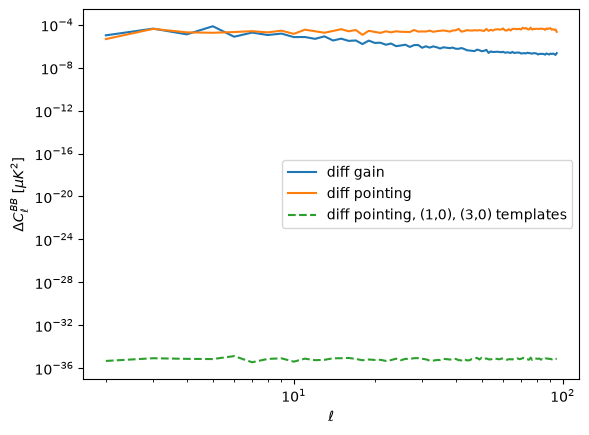

In [6]:
qu_basis = sbm.Basis.qu(hwp=False)
mask = hmaps.crosslink_mask(1.0)
pair = sy.sky_signal(sky, pair_difference=True)
ideal_pair = sbm.map_make((hmaps, pair), qu_basis, mask=mask).iqu
models = {
    "diff gain": pair + sy.diff_gain(sky, g_t=1e-3, g_b=-1e-3),
    "diff pointing": pair + sy.diff_pointing(sky, rho, 0.0, rho, np.pi / 2),
}
for name, m in models.items():
    plt.loglog(ell[2:], bb_of(residual(m, qu_basis, ideal_pair))[2:], label=name)
pointing = residual(models["diff pointing"], qu_basis.extend([(1, 0), (3, 0)]), ideal_pair)
plt.loglog(ell[2:], bb_of(pointing)[2:], "--", label="diff pointing, (1,0), (3,0) templates")
plt.xlabel(r"$\ell$"); plt.ylabel(r"$\Delta C_\ell^{BB}$ [$\mu K^2$]"); plt.legend()

## White noise

`noise_maps` draws white noise with the covariance $\sigma^2 A^{-1}/N_{\rm hits}$ of
the map-maker, correlations between the components included. Templates cost noise.

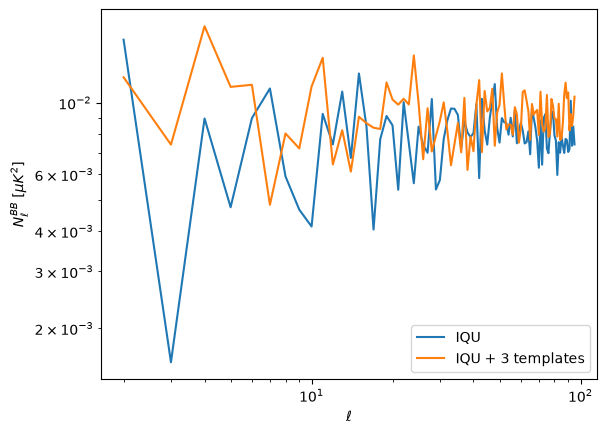

In [7]:
rng = np.random.default_rng(1)
for basis, label in ((iqu_basis, "IQU"), (iqu_basis.extend([(1, 0), (3, -4), (1, -4)]), "IQU + 3 templates")):
    noise = sbm.noise_maps(hmaps, basis, net_ukrts=100.0, sampling_rate_hz=hmaps.sampling_rate_hz, rng=rng).iqu
    plt.loglog(ell[2:], bb_of(noise)[2:], label=label)
plt.xlabel(r"$\ell$"); plt.ylabel(r"$N_\ell^{BB}$ [$\mu K^2$]"); plt.legend()